# **Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación**

## Integrantes
- Laura Sanchez Bernal - 202411353
- Baruc Jeronimo Triana Bastidas - 202416093

## Planteamiento del problema

DermAlpes necesita delimitar la lesión en fotografías dermatoscópicas para apoyar la revisión de un especialista. Se plantea una tarea de **agrupación no supervisada de píxeles**: K-medias forma grupos a partir de color RGB y posición; después, una regla automática convierte los grupos en una máscara binaria. La máscara de referencia se utiliza solamente para ajustar la configuración en 15 imágenes y evaluar el resultado final en otras cinco. El método no produce diagnósticos.

Se sigue la separación de ajuste y prueba indicada en el enunciado. La fuente de las imágenes y máscaras es [ISIC 2016, tarea de segmentación de lesiones](https://challenge.isic-archive.com/landing/2016/37/).

## 1. Importación de librerías y protocolo

Se fija la semilla `2611` para el muestreo y K-medias. El análisis se realiza a una resolución de 80 × 80 píxeles, suficiente para comparar configuraciones en este laboratorio sin ajustar sobre las imágenes de prueba. Cada agrupación se ajusta sobre 1.200 píxeles y la silueta se calcula sobre 300 de ellos; luego se asignan grupos a todos los píxeles de la imagen. Se exploran K de 2 a 8.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MPLCONFIGDIR"] = "/private/tmp/lab4_matplotlib"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_fill_holes, binary_opening, label
from scipy.spatial.distance import pdist, squareform
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)
from IPython.display import display

SEMILLA = 2611
LADO = 80
N_AJUSTE_KMEDIAS = 1200
N_SILUETA = 300
RUTA = Path("datos")
AJUSTE = ["ISIC_" + x for x in ["0000085", "0000086", "0000089", "0000094", "0000108",
    "0000114", "0000116", "0000122", "0000133", "0000137", "0000150", "0000153",
    "0000156", "0000157", "0000112"]]
PRUEBA = ["ISIC_" + x for x in ["0000087", "0000105", "0000110", "0000123", "0000128"]]
assert len(AJUSTE) == 15 and len(PRUEBA) == 5 and not (set(AJUSTE) & set(PRUEBA))
print(f"{len(AJUSTE)} imágenes de ajuste y {len(PRUEBA)} de prueba; semilla {SEMILLA}.")

15 imágenes de ajuste y 5 de prueba; semilla 2611.


### 1.1. Carga y calidad de las imágenes

Se revisan completitud, dimensiones y valores de las máscaras. Las 15 imágenes RGB de ajuste y sus máscaras deben existir por pares. La interpolación bilineal suaviza la imagen reducida; la máscara se redimensiona por **vecino más cercano** para conservar las etiquetas 0 y 1. Las máscaras de prueba permanecen sin abrir hasta la evaluación final.

In [2]:
def cargar_imagen(identificador, incluir_mascara=True):
    ruta_imagen = RUTA / "imagenes" / f"{identificador}.jpg"
    imagen = np.asarray(Image.open(ruta_imagen).convert("RGB").resize(
        (LADO, LADO), Image.Resampling.BILINEAR))
    if not incluir_mascara:
        return imagen
    ruta_mascara = RUTA / "mascaras" / f"{identificador}_Segmentation.png"
    mascara = np.asarray(Image.open(ruta_mascara).convert("L").resize(
        (LADO, LADO), Image.Resampling.NEAREST)) >= 128
    return imagen, mascara

revision = []
for identificador in AJUSTE:
    ruta_i = RUTA / "imagenes" / f"{identificador}.jpg"
    ruta_m = RUTA / "mascaras" / f"{identificador}_Segmentation.png"
    assert ruta_i.exists() and ruta_m.exists(), f"Falta imagen o máscara: {identificador}"
    with Image.open(ruta_i) as original, Image.open(ruta_m) as mascara_original:
        valores = set(np.unique(np.asarray(mascara_original)).tolist())
        revision.append({"imagen": identificador, "conjunto": "ajuste" if identificador in AJUSTE else "prueba",
                         "ancho": original.width, "alto": original.height,
                         "mascara_binaria_original": valores <= {0, 255}})
revision = pd.DataFrame(revision)
assert revision["mascara_binaria_original"].all()
assert all(cargar_imagen(i)[0].shape[:2] == cargar_imagen(i)[1].shape for i in AJUSTE)
display(revision.groupby("conjunto").agg(imagenes=("imagen", "count"),
    ancho_min=("ancho", "min"), ancho_max=("ancho", "max"),
    alto_min=("alto", "min"), alto_max=("alto", "max")))

,imagenes,ancho_min,ancho_max,alto_min,alto_max
conjunto,,,,,
ajuste,15,963,2592,629,1944


Las 15 parejas de ajuste están completas y las máscaras originales contienen únicamente los valores esperados. Las resoluciones originales varían; por eso se comparan los resultados después del mismo redimensionamiento en imagen y máscara.

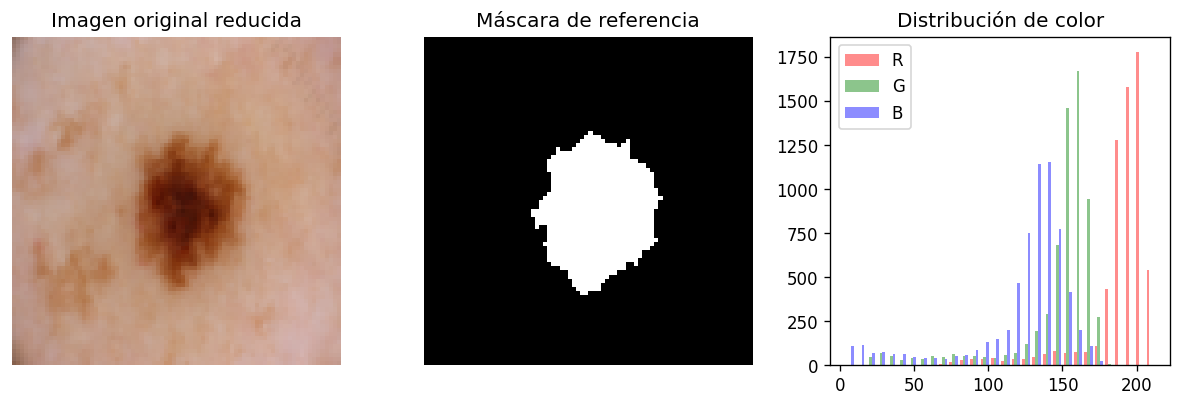

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
imagen_ejemplo, mascara_ejemplo = cargar_imagen(AJUSTE[0])
axes[0].imshow(imagen_ejemplo); axes[0].set_title("Imagen original reducida")
axes[1].imshow(mascara_ejemplo, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Máscara de referencia")
axes[2].hist(imagen_ejemplo.reshape(-1, 3), bins=30, color=["r", "g", "b"],
             label=["R", "G", "B"], alpha=.45)
axes[2].set_title("Distribución de color")
for ax in axes[:2]: ax.axis("off")
axes[2].legend(); plt.tight_layout(); plt.show()

## 2. Pipeline de representación

Siguiendo la preparación de imágenes vista en clase, cada fila representa un píxel. Se normalizan R, G y B dividiendo entre 255, y las coordenadas `x` e `y` dividiendo entre el máximo de cada eje. El transformador de Scikit-learn produce `[β·R, β·G, β·B, λ·x, λ·y]`. Así, β y λ se cambian como parámetros, sin modificar la implementación. La distancia euclídea de K-medias considera el peso relativo de color y ubicación.

In [4]:
class PixelesRGBPosicion(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        alto, ancho, _ = X.shape
        yy, xx = np.indices((alto, ancho))
        rgb = X.reshape(-1, 3).astype(np.float64) / 255.0
        return np.column_stack((self.beta * rgb,
            self.lam * (xx / (ancho - 1)).ravel(),
            self.lam * (yy / (alto - 1)).ravel())).astype(np.float64)

representacion = Pipeline([("pixeles", PixelesRGBPosicion(beta=1, lam=.2))])
matriz_ejemplo = representacion.fit_transform(imagen_ejemplo)
print("Dimensiones:", matriz_ejemplo.shape)
display(pd.DataFrame(matriz_ejemplo[:5], columns=["βR", "βG", "βB", "λx", "λy"]))
assert matriz_ejemplo.shape == (LADO * LADO, 5)

Dimensiones: (6400, 5)


,βR,βG,βB,λx,λy
0,0.552941,0.427451,0.384314,0.000000,0.0
1,0.596078,0.478431,0.435294,0.002532,0.0
2,0.643137,0.517647,0.478431,0.005063,0.0
3,0.678431,0.549020,0.501961,0.007595,0.0
4,0.721569,0.600000,0.564706,0.010127,0.0


### 2.1. Combinaciones de β y λ

Se prueban diez razones distintas λ/β: color solo, ocho pesos espaciales crecientes y posición sola. Multiplicar ambos pesos por la misma constante no altera las distancias relativas, por lo que no se repiten razones equivalentes. Las configuraciones de un solo atributo sirven como referencias para interpretar el aporte de la posición.

In [5]:
PESOS = [(1, 0), (1, .05), (1, .10), (1, .20), (1, .35),
         (1, .50), (1, .75), (1, 1), (1, 2), (0, 1)]
pd.DataFrame(PESOS, columns=["β", "λ"]).assign(
    razon=lambda t: t.apply(lambda f: "solo posición" if f["β"] == 0 else f["λ"] / f["β"], axis=1))

,β,λ,razon
0,1,0.00,0.0
1,1,0.05,0.05
2,1,0.10,0.1
3,1,0.20,0.2
4,1,0.35,0.35
5,1,0.50,0.5
6,1,0.75,0.75
7,1,1.00,1.0
8,1,2.00,2.0
9,0,1.00,solo posición


## 3. Selección de K y construcción de la máscara

Para cada imagen y combinación de pesos se ajusta K-medias con K entre 2 y 8. Se selecciona el K de mayor silueta calculada sobre una muestra reproducible de 300 píxeles, sin usar la máscara de referencia. `n_init=3` reduce la dependencia de una sola inicialización. Después se asigna un grupo a los 6.400 píxeles.

La silueta es una medida **intrínseca** de cohesión y separación. Los identificadores de los grupos no tienen significado clínico: todavía se necesita una regla que indique cuáles píxeles son lesión.

### 3.1. Dos criterios automáticos

1. **Grupo oscuro:** se selecciona el grupo con menor luminancia RGB promedio. Es una referencia sencilla que puede confundir sombras o bordes.
2. **Contraste y componente central:** se calcula la luminancia mediana del borde como referencia de piel. Se reúnen los grupos al menos 0,04 unidades más oscuros, se aplica una apertura mínima para quitar píxeles aislados y se elige el componente con mayor área penalizada por la distancia al centro. Al final se rellenan sus huecos. Si ningún grupo supera el umbral, se usa el más oscuro. Estas reglas no consultan la máscara de referencia durante la predicción.

La regla central supone que la lesión está cerca del centro, lo cual puede fallar cuando el encuadre es distinto. La máscara estimada es binaria y considera la lesión como clase positiva.

In [6]:
def construir_mascara(imagen, grupos, criterio):
    alto, ancho = grupos.shape
    numero_grupos = grupos.max() + 1
    rgb = imagen.astype(float) / 255.0
    pesos_luminancia = np.array([.299, .587, .114])
    luminancias = np.array([
        np.sum(rgb[grupos == j].mean(axis=0) * pesos_luminancia)
        for j in range(numero_grupos)])
    if criterio == "oscuro":
        return grupos == np.argmin(luminancias)
    if criterio != "contraste_central":
        raise ValueError("Criterio desconocido")

    borde = np.zeros((alto, ancho), dtype=bool)
    borde[:8] = borde[-8:] = True
    borde[:, :8] = borde[:, -8:] = True
    luminancia_borde = np.median(np.sum(rgb[borde] * pesos_luminancia, axis=1))
    candidatos = np.flatnonzero(luminancias < luminancia_borde - .04)
    if len(candidatos) == 0:
        candidatos = np.array([np.argmin(luminancias)])
    mascara = binary_opening(np.isin(grupos, candidatos), iterations=1)
    componentes, n = label(mascara)
    if n:
        yy, xx = np.indices((alto, ancho))
        centro = np.array([(alto - 1) / 2, (ancho - 1) / 2])
        puntajes = []
        for j in range(1, n + 1):
            pixeles = componentes == j
            area = pixeles.sum()
            posicion = np.array([yy[pixeles].mean(), xx[pixeles].mean()])
            distancia = np.linalg.norm((posicion - centro) / centro)
            puntajes.append(area / (1 + distancia))
        mascara = componentes == (np.argmax(puntajes) + 1)
    return binary_fill_holes(mascara)

### 3.2. Función de evaluación

El **Dice** compara la máscara final con la referencia y es el criterio principal de selección. El **V-measure** compara las etiquetas de los grupos con las etiquetas binarias de referencia y sirve como información complementaria: puede ser distinto del Dice porque una agrupación puede estar bien separada sin identificar toda la lesión. Precisión y recall también consideran la lesión como clase positiva.

In [7]:
def agrupar_y_evaluar(imagen, mascara_real, beta, lam):
    X = Pipeline([("pixeles", PixelesRGBPosicion(beta, lam))]).fit_transform(imagen)
    rng = np.random.default_rng(SEMILLA)
    indices_ajuste = rng.choice(len(X), min(N_AJUSTE_KMEDIAS, len(X)), replace=False)
    indices_silueta = rng.choice(len(indices_ajuste),
                                  min(N_SILUETA, len(indices_ajuste)), replace=False)
    muestra = X[indices_ajuste]
    siluetas, modelos = [], []
    for k in range(2, 9):
        # En algunas instalaciones NumPy emite avisos numéricos espurios en matmul;
        # se verifican explícitamente centros y siluetas finitos.
        with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
            modelo = KMeans(n_clusters=k, n_init=3, max_iter=100,
                            random_state=SEMILLA).fit(muestra)
        assert np.isfinite(modelo.cluster_centers_).all()
        etiquetas_muestra = modelo.labels_[indices_silueta]
        if len(np.unique(etiquetas_muestra)) > 1:
            distancias = squareform(pdist(muestra[indices_silueta]))
            silueta = silhouette_score(distancias, etiquetas_muestra,
                                       metric="precomputed")
        else:
            silueta = -1
        assert np.isfinite(silueta)
        modelos.append(modelo)
        siluetas.append(silueta)
    indice_mejor = int(np.argmax(siluetas))
    k_final = indice_mejor + 2
    grupos = modelos[indice_mejor].predict(X).reshape(imagen.shape[:2])
    v = v_measure_score(mascara_real.ravel(), grupos.ravel())
    resultados = []
    mascaras_estimadas = {}
    for criterio in ["oscuro", "contraste_central"]:
        estimada = construir_mascara(imagen, grupos, criterio)
        mascaras_estimadas[criterio] = estimada
        resultados.append({"criterio": criterio, "K": k_final,
            "silueta": siluetas[indice_mejor],
            "Dice": f1_score(mascara_real.ravel(), estimada.ravel(), zero_division=0),
            "V-measure": v,
            "precision": precision_score(mascara_real.ravel(), estimada.ravel(), zero_division=0),
            "recall": recall_score(mascara_real.ravel(), estimada.ravel(), zero_division=0)})
    return resultados, grupos, mascaras_estimadas, siluetas

resultados_ejemplo, grupos_ejemplo, mascaras_ejemplo, siluetas_ejemplo = agrupar_y_evaluar(
    imagen_ejemplo, mascara_ejemplo, 1, .2)
display(pd.DataFrame({"K": range(2, 9), "silueta": siluetas_ejemplo}))
display(pd.DataFrame(resultados_ejemplo))

,K,silueta
0,2,0.706868
1,3,0.319409
2,4,0.311670
3,5,0.310390
4,6,0.335292
5,7,0.359525
6,8,0.374937


,criterio,K,silueta,Dice,V-measure,precision,recall
0,oscuro,2,0.706868,0.914286,0.779608,0.991354,0.848335
1,contraste_central,2,0.706868,0.913597,0.779608,1.000000,0.840937


## 4. Ajuste con las 15 imágenes

Se evalúan 150 combinaciones de imagen y pesos, cada una con dos criterios de máscara. K se selecciona siempre por silueta antes de calcular Dice o V-measure. Las métricas de referencia se consultan únicamente en el conjunto de ajuste para comparar configuraciones; las cinco imágenes de prueba permanecen reservadas.

In [8]:
filas_ajuste = []
for identificador in AJUSTE:
    imagen, referencia = cargar_imagen(identificador)
    for beta, lam in PESOS:
        resultados, _, _, _ = agrupar_y_evaluar(imagen, referencia, beta, lam)
        for resultado in resultados:
            filas_ajuste.append({"imagen": identificador, "β": beta, "λ": lam, **resultado})
tabla_ajuste = pd.DataFrame(filas_ajuste)
assert len(tabla_ajuste) == 15 * 10 * 2
print("Evaluaciones:", len(tabla_ajuste))
display(tabla_ajuste.head())

Evaluaciones: 300


,imagen,β,λ,criterio,K,silueta,Dice,V-measure,precision,recall
0,ISIC_0000085,1,0.00,oscuro,2,0.803884,0.913564,0.778310,0.991342,0.847102
1,ISIC_0000085,1,0.00,contraste_central,2,0.803884,0.912869,0.778310,1.000000,0.839704
2,ISIC_0000085,1,0.05,oscuro,2,0.793358,0.914286,0.779608,0.991354,0.848335
3,ISIC_0000085,1,0.05,contraste_central,2,0.793358,0.913597,0.779608,1.000000,0.840937
4,ISIC_0000085,1,0.10,oscuro,2,0.769780,0.914286,0.779608,0.991354,0.848335


### 4.1. Comparación de configuraciones

El Dice promedio sobre las 15 imágenes define la selección. Se reportan también la silueta y el V-measure promedio; estos últimos describen los grupos y no reemplazan la evaluación de la máscara. Las configuraciones de solo color y solo posición permanecen visibles como referencias.

In [9]:
resumen = (tabla_ajuste.groupby(["β", "λ", "criterio"], as_index=False)
    .agg(Dice_promedio=("Dice", "mean"), V_promedio=("V-measure", "mean"),
         silueta_promedio=("silueta", "mean"))
    .sort_values("Dice_promedio", ascending=False).reset_index(drop=True))
display(resumen.round(4))

,β,λ,criterio,Dice_promedio,V_promedio,silueta_promedio
0,1,0.20,contraste_central,0.8917,0.6247,0.6467
1,1,0.35,contraste_central,0.8874,0.5871,0.5366
2,1,0.05,contraste_central,0.8857,0.6466,0.7407
3,1,0.00,contraste_central,0.8857,0.6467,0.7514
4,1,0.35,oscuro,0.8607,0.5871,0.5366
5,1,0.10,contraste_central,0.8568,0.6196,0.7040
6,1,0.20,oscuro,0.8564,0.6247,0.6467
7,1,0.00,oscuro,0.8463,0.6467,0.7514
8,1,0.05,oscuro,0.8463,0.6466,0.7407
9,1,0.50,contraste_central,0.8454,0.5070,0.4718


La mayor media de ajuste corresponde a **β=1, λ=0,2 y contraste central**, con Dice **0,8917**. Le siguen β=1, λ=0,35 con Dice **0,8874**, y β=1, λ=0,05 con **0,8857**. Solo color con el mismo criterio alcanza **0,8857**, mientras que solo posición baja a **0,3384**. Por tanto, el color aporta la mayor parte de la separación; una dosis moderada de posición mejora algunos casos sin dominar las distancias.

criterio,β,λ,contraste_central,oscuro,ventaja_contraste
0,0,1.00,0.3384,0.2605,0.0779
1,1,0.00,0.8857,0.8463,0.0393
2,1,0.05,0.8857,0.8463,0.0395
3,1,0.10,0.8568,0.8169,0.0398
4,1,0.20,0.8917,0.8564,0.0353
5,1,0.35,0.8874,0.8607,0.0267
6,1,0.50,0.8454,0.8300,0.0155
7,1,0.75,0.8262,0.7410,0.0853
8,1,1.00,0.7514,0.7395,0.0118
9,1,2.00,0.6025,0.6747,-0.0722


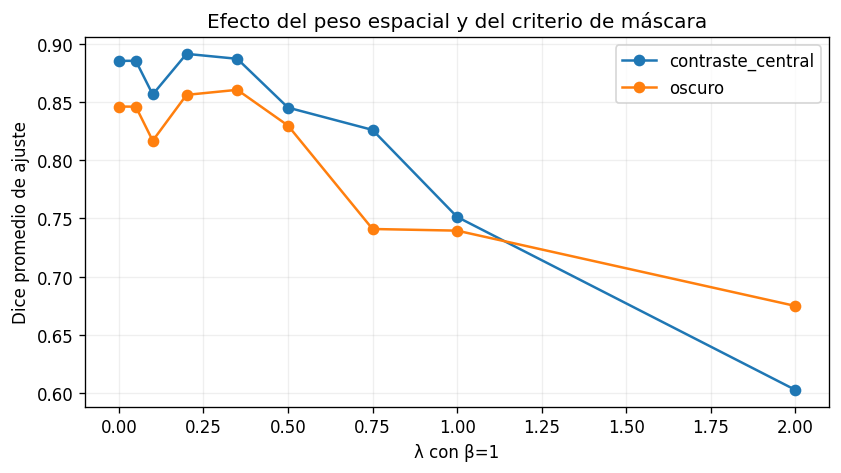

In [10]:
comparacion_criterios = (resumen.pivot(index=["β", "λ"], columns="criterio",
                                     values="Dice_promedio").reset_index())
comparacion_criterios["ventaja_contraste"] = (comparacion_criterios["contraste_central"]
                                             - comparacion_criterios["oscuro"])
display(comparacion_criterios.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for criterio, sub in resumen[resumen["β"] == 1].groupby("criterio"):
    ax.plot(sub.sort_values("λ")["λ"], sub.sort_values("λ")["Dice_promedio"],
            marker="o", label=criterio)
ax.set(xlabel="λ con β=1", ylabel="Dice promedio de ajuste",
       title="Efecto del peso espacial y del criterio de máscara")
ax.legend(); ax.grid(alpha=.2); plt.show()

### 4.2. Resultados por imagen y casos de fallo

La configuración seleccionada obtiene Dice entre **0,755** y **0,977** en ajuste. Los valores más bajos se presentan en `ISIC_0000116`, `ISIC_0000112` y `ISIC_0000150`, donde el recall muestra que la máscara estimada omite zonas claras o difusas de la lesión. La precisión alta en estas imágenes indica que el error principal es dejar lesión por fuera, no incluir piel de más.

In [11]:
seleccion_ajuste = tabla_ajuste.query('β == 1 and λ == 0.2 and criterio == "contraste_central"')
display(seleccion_ajuste[["imagen", "K", "silueta", "Dice", "V-measure", "precision", "recall"]]
        .sort_values("Dice").round(4))
print("K seleccionados:", seleccion_ajuste["K"].value_counts().sort_index().to_dict())

K seleccionados: {2: 14, 4: 1}


,imagen,K,silueta,Dice,V-measure,precision,recall
127,ISIC_0000116,2,0.6516,0.7545,0.4803,1.0000,0.6058
287,ISIC_0000112,2,0.5897,0.7831,0.4369,1.0000,0.6435
207,ISIC_0000150,2,0.6593,0.7923,0.5862,1.0000,0.6560
267,ISIC_0000157,2,0.6892,0.8624,0.6375,1.0000,0.7581
167,ISIC_0000133,2,0.6237,0.8873,0.4322,0.9865,0.8062
107,ISIC_0000114,2,0.6901,0.8904,0.4065,0.8263,0.9653
147,ISIC_0000122,2,0.5726,0.9014,0.6607,0.9886,0.8283
7,ISIC_0000085,2,0.7069,0.9136,0.7796,1.0000,0.8409
87,ISIC_0000108,2,0.7185,0.9195,0.7869,1.0000,0.8510
247,ISIC_0000156,2,0.7336,0.9237,0.7168,1.0000,0.8581


### 4.2.1. Revisión visual de los casos difíciles

Las dos imágenes de ajuste con menor Dice muestran por qué conviene revisar las máscaras además del promedio. Se compara la fotografía, la estimación y la referencia, manteniendo fija la configuración seleccionada.

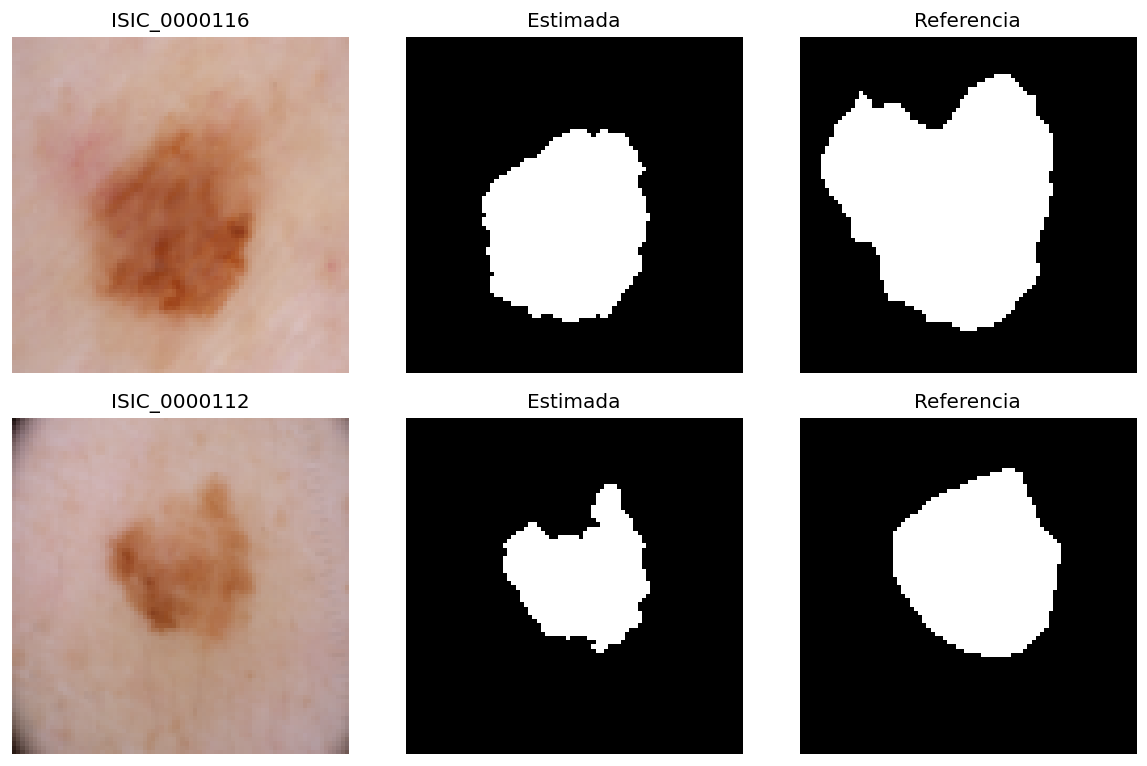

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for fila, identificador in enumerate(seleccion_ajuste.nsmallest(2, "Dice")["imagen"]):
    imagen, referencia = cargar_imagen(identificador)
    _, _, mascaras, _ = agrupar_y_evaluar(imagen, referencia, 1, .2)
    estimada = mascaras["contraste_central"]
    for columna, (matriz, titulo, mapa) in enumerate([
        (imagen, identificador, None), (estimada, "Estimada", "gray"),
        (referencia, "Referencia", "gray")]):
        axes[fila, columna].imshow(matriz, cmap=mapa,
                                  vmin=0 if mapa else None, vmax=1 if mapa else None)
        axes[fila, columna].set_title(titulo)
        axes[fila, columna].axis("off")
plt.tight_layout(); plt.show()

En `ISIC_0000116` (Dice **0,755**) y `ISIC_0000112` (Dice **0,783**) la estimación conserva el centro oscuro, pero recorta partes periféricas de la lesión. Sus recalls de **0,606** y **0,643** muestran que el problema dominante son los falsos negativos; la precisión de **1,000** en ambas indica que casi no se incluye piel adicional.

### 4.2.1. Cambio de Dice por incluir posición

Para identificar dónde ayuda o perjudica λ=0,2, se compara por imagen con β=1, λ=0 manteniendo el mismo criterio de máscara. La diferencia se calcula sobre las 15 imágenes de ajuste; el signo positivo favorece incluir posición.

In [13]:
solo_color = tabla_ajuste.query('β == 1 and λ == 0 and criterio == "contraste_central"')
comparacion_posicion = (seleccion_ajuste[["imagen", "Dice"]]
    .merge(solo_color[["imagen", "Dice"]], on="imagen", suffixes=("_color_posicion", "_solo_color")))
comparacion_posicion["cambio_Dice"] = (comparacion_posicion["Dice_color_posicion"]
                                        - comparacion_posicion["Dice_solo_color"])
display(comparacion_posicion.sort_values("cambio_Dice", ascending=False).round(4))

,imagen,Dice_color_posicion,Dice_solo_color,cambio_Dice
3,ISIC_0000094,0.9352,0.8449,0.0903
4,ISIC_0000108,0.9195,0.9140,0.0055
0,ISIC_0000085,0.9136,0.9129,0.0007
1,ISIC_0000086,0.9302,0.9302,0.0000
2,ISIC_0000089,0.9508,0.9508,0.0000
5,ISIC_0000114,0.8904,0.8904,0.0000
7,ISIC_0000122,0.9014,0.9014,0.0000
9,ISIC_0000137,0.9537,0.9537,0.0000
12,ISIC_0000156,0.9237,0.9237,0.0000
14,ISIC_0000112,0.7831,0.7831,0.0000


La mejora está concentrada en `ISIC_0000094` (+0,090). En `ISIC_0000133` y `ISIC_0000116` la reducción es pequeña (menos de 0,004). Esto evita atribuir el aumento promedio a una mejora uniforme en todas las fotografías.

### 4.3. Comparación visual de los grupos

Se muestran dos imágenes de ajuste, una con lesión oscura y otra con contorno más tenue. Para cada una se presentan la imagen y los grupos de las dos mejores configuraciones, además de solo color y solo posición. La visualización permite reconocer que un grupo compacto no siempre coincide con la región completa de la lesión.

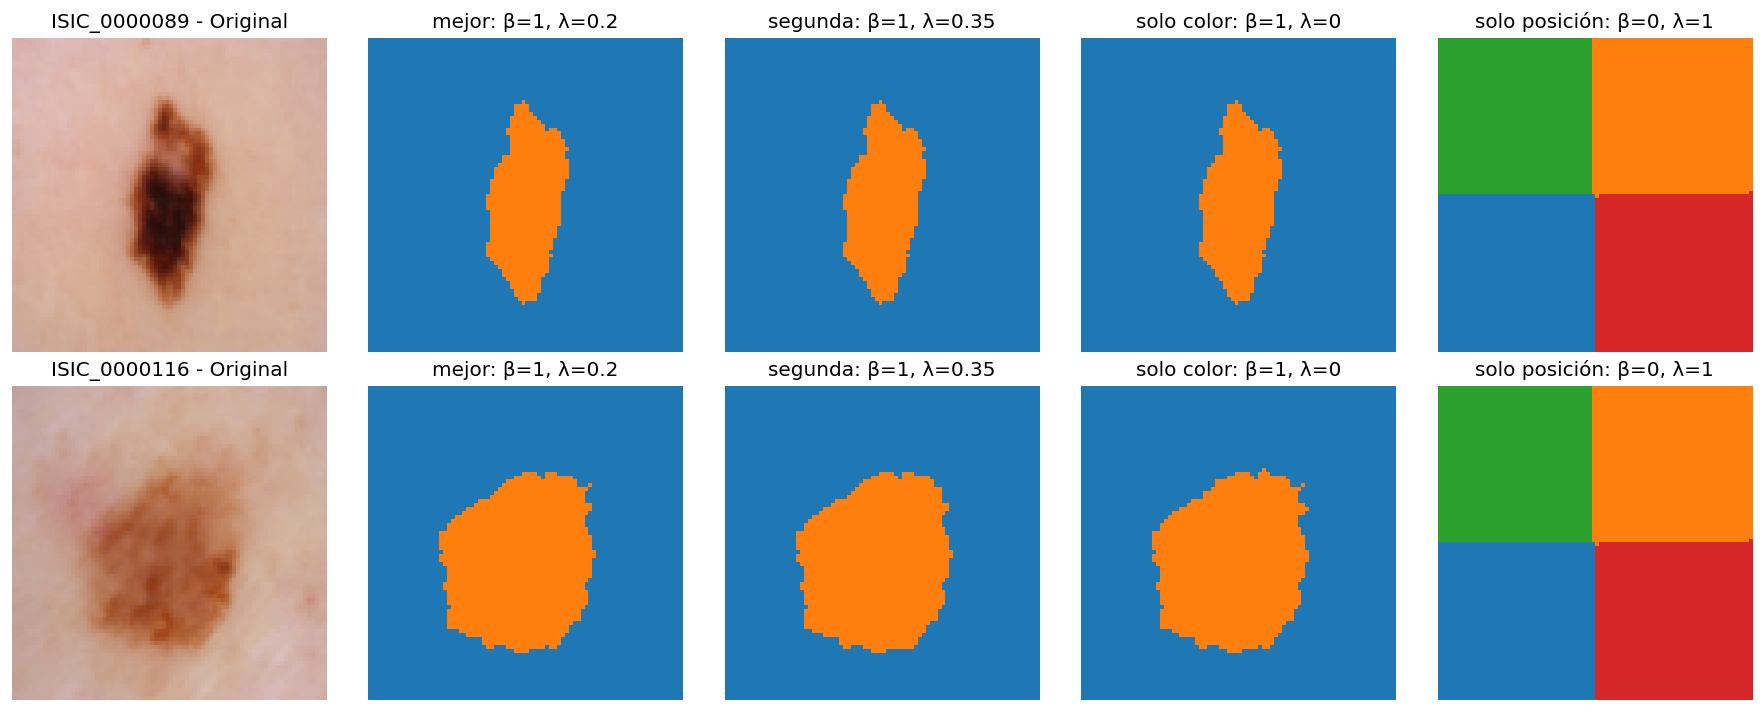

In [14]:
configuraciones_visuales = [(1, .20, "mejor"), (1, .35, "segunda"),
                          (1, 0, "solo color"), (0, 1, "solo posición")]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for fila, identificador in enumerate(["ISIC_0000089", "ISIC_0000116"]):
    imagen, referencia = cargar_imagen(identificador)
    axes[fila, 0].imshow(imagen)
    axes[fila, 0].set_title(f"{identificador} - Original")
    for columna, (beta, lam, nombre) in enumerate(configuraciones_visuales, start=1):
        _, grupos, _, _ = agrupar_y_evaluar(imagen, referencia, beta, lam)
        axes[fila, columna].imshow(grupos, cmap="tab10", vmin=0, vmax=9,
                                  interpolation="nearest")
        axes[fila, columna].set_title(f"{nombre}: β={beta}, λ={lam}")
    for ax in axes[fila]: ax.axis("off")
plt.tight_layout(); plt.show()

### 4.3.1. De grupos a máscara en las cuatro configuraciones

Para `ISIC_0000094`, la imagen que más mejora al incluir posición, se muestran también las máscaras resultantes. Esto permite comprobar si el cambio en los grupos se traduce en una delimitación más cercana a la referencia.

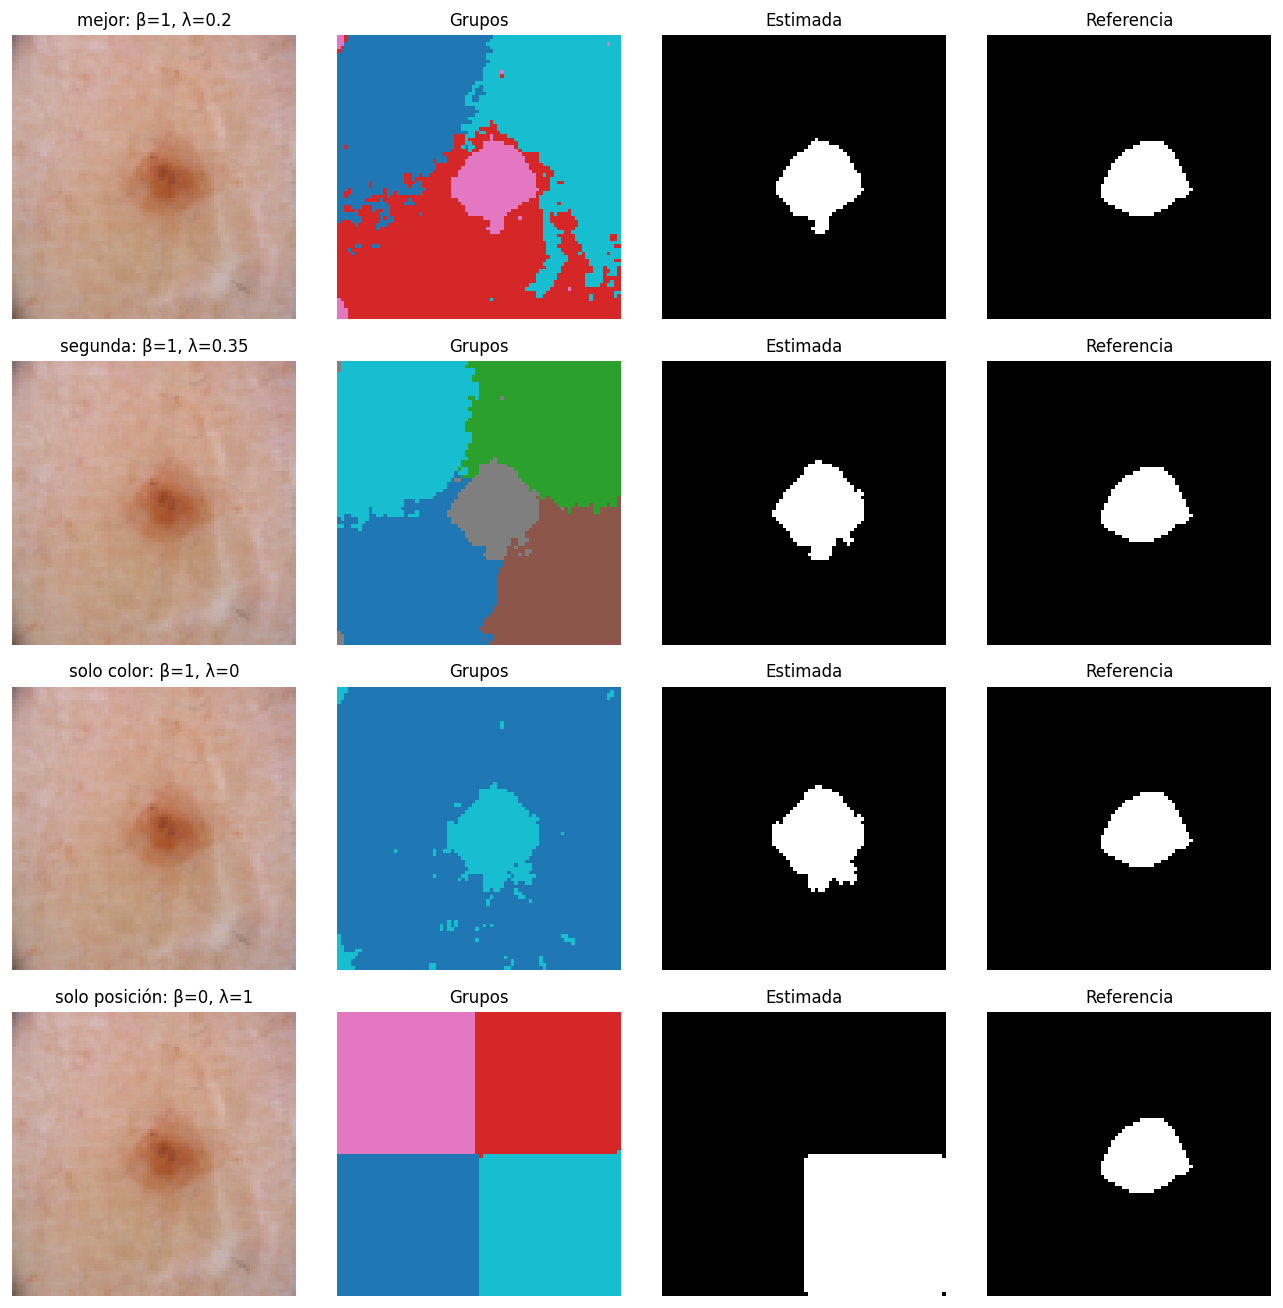

In [15]:
identificador = "ISIC_0000094"
imagen, referencia = cargar_imagen(identificador)
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for fila, (beta, lam, nombre) in enumerate(configuraciones_visuales):
    _, grupos, mascaras, _ = agrupar_y_evaluar(imagen, referencia, beta, lam)
    estimada = mascaras["contraste_central"]
    for columna, (matriz, titulo, mapa) in enumerate([
        (imagen, f"{nombre}: β={beta}, λ={lam}", None),
        (grupos, "Grupos", "tab10"), (estimada, "Estimada", "gray"),
        (referencia, "Referencia", "gray")]):
        axes[fila, columna].imshow(matriz, cmap=mapa,
            vmin=0 if mapa == "gray" else None,
            vmax=1 if mapa == "gray" else None, interpolation="nearest")
        axes[fila, columna].set_title(titulo, fontsize=10)
        axes[fila, columna].axis("off")
plt.tight_layout(); plt.show()

### 4.3.1. Silueta y Dice en las imágenes de ajuste

La siguiente gráfica contrasta la métrica intrínseca empleada para K con la superposición de la máscara. Se resaltan `ISIC_0000094` y `ISIC_0000116`, que ilustran que ambas medidas responden a objetivos distintos.

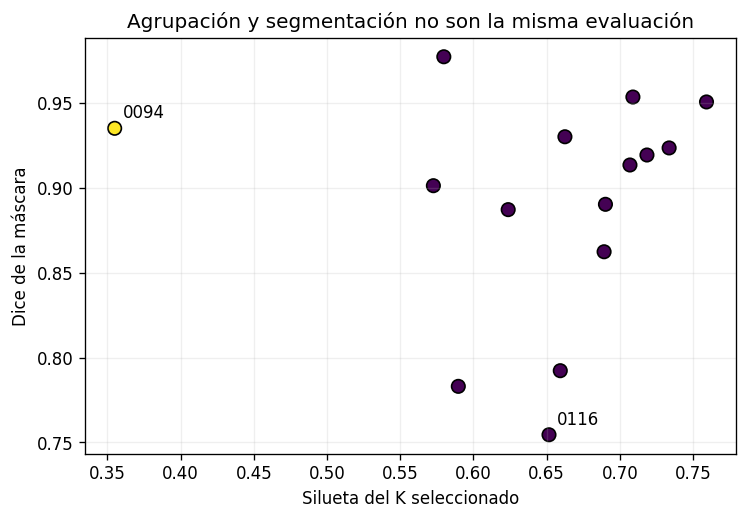

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(seleccion_ajuste["silueta"], seleccion_ajuste["Dice"],
           c=seleccion_ajuste["K"], cmap="viridis", s=65, edgecolor="black")
for identificador in ["ISIC_0000094", "ISIC_0000116"]:
    fila = seleccion_ajuste.set_index("imagen").loc[identificador]
    ax.annotate(identificador[-4:], (fila["silueta"], fila["Dice"]),
                xytext=(5, 6), textcoords="offset points")
ax.set(xlabel="Silueta del K seleccionado", ylabel="Dice de la máscara",
       title="Agrupación y segmentación no son la misma evaluación")
ax.grid(alpha=.2); plt.show()

### 4.4. Selección final

Se conserva **β=1, λ=0,2, K elegido por la silueta de cada imagen y criterio de contraste central**. K=2 resultó seleccionado en 14 de las 15 imágenes de ajuste; `ISIC_0000094` seleccionó K=4. En esta última, agregar posición elevó el Dice de **0,845** con solo color a **0,935**. La regla de contraste central supera al grupo más oscuro (Dice medio **0,892** frente a **0,856** con β=1, λ=0,2). El resultado se eligió con ajuste y se fija ahora antes de consultar prueba.

In [17]:
CONFIGURACION_FINAL = {"beta": 1, "lam": .2, "criterio": "contraste_central"}
assert resumen.iloc[0][["β", "λ", "criterio"]].tolist() == [1, .2, "contraste_central"]
print(CONFIGURACION_FINAL)

{'beta': 1, 'lam': 0.2, 'criterio': 'contraste_central'}


## 5. Evaluación en las cinco imágenes de prueba

Se aplica la configuración ya fijada. La selección de K usa únicamente la silueta de los píxeles de cada imagen; las máscaras de prueba se abren después para calcular las métricas. No se cambian pesos, criterio, resolución, umbrales ni semilla a partir de estos resultados.

In [18]:
filas_prueba = []
visualizaciones_prueba = {}
for identificador in PRUEBA:
    imagen, referencia = cargar_imagen(identificador)
    resultados, grupos, estimadas, _ = agrupar_y_evaluar(
        imagen, referencia, CONFIGURACION_FINAL["beta"], CONFIGURACION_FINAL["lam"])
    elegido = next(r for r in resultados if r["criterio"] == CONFIGURACION_FINAL["criterio"])
    filas_prueba.append({"imagen": identificador, **elegido})
    visualizaciones_prueba[identificador] = (imagen, estimadas["contraste_central"], referencia)
tabla_prueba = pd.DataFrame(filas_prueba)
display(tabla_prueba[["imagen", "K", "silueta", "Dice", "V-measure", "precision", "recall"]].round(4))

,imagen,K,silueta,Dice,V-measure,precision,recall
0,ISIC_0000087,2,0.6613,0.8816,0.6377,1.0000,0.7883
1,ISIC_0000105,2,0.7061,0.9314,0.7781,1.0000,0.8716
2,ISIC_0000110,2,0.6554,0.7589,0.3192,1.0000,0.6115
3,ISIC_0000123,2,0.6593,0.9037,0.7051,0.8559,0.9572
4,ISIC_0000128,2,0.7162,0.9442,0.8434,1.0000,0.8943


### 5.1. Mapa de errores

Para los dos casos de prueba que requieren mayor revisión se señalan falsos positivos en rojo y falsos negativos en azul. Esta vista facilita relacionar precisión y recall con los bordes que realmente se incluyeron o se omitieron.

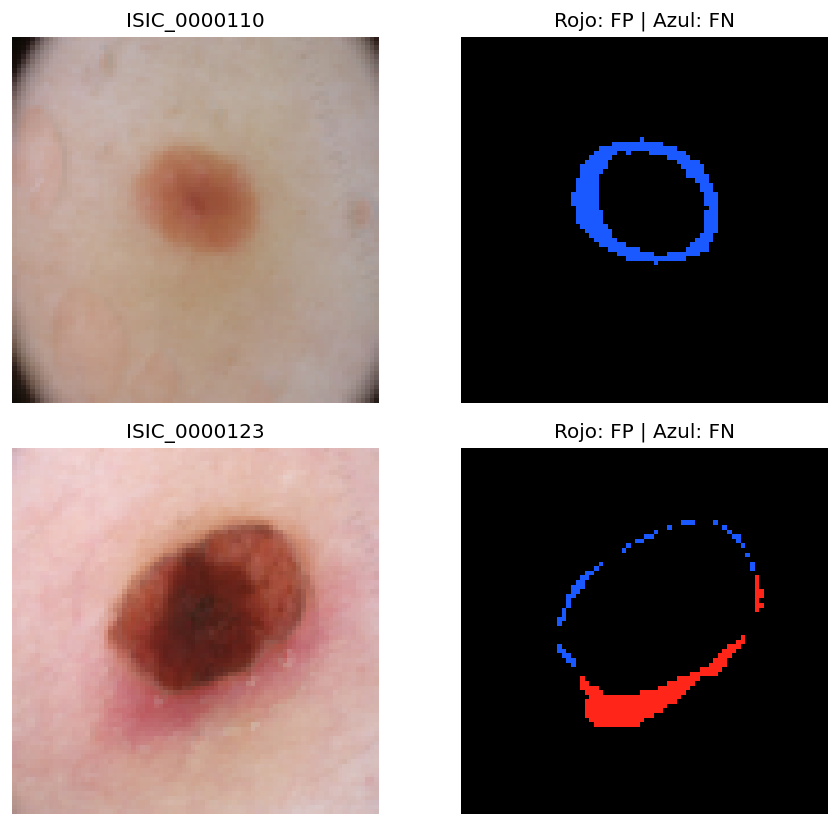

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for fila, identificador in enumerate(["ISIC_0000110", "ISIC_0000123"]):
    imagen, estimada, referencia = visualizaciones_prueba[identificador]
    errores = np.zeros((*estimada.shape, 3), dtype=float)
    errores[estimada & ~referencia] = [1, .15, .1]  # falso positivo
    errores[~estimada & referencia] = [.1, .35, 1]  # falso negativo
    axes[fila, 0].imshow(imagen); axes[fila, 0].set_title(identificador)
    axes[fila, 1].imshow(errores); axes[fila, 1].set_title("Rojo: FP | Azul: FN")
    for ax in axes[fila]: ax.axis("off")
plt.tight_layout(); plt.show()

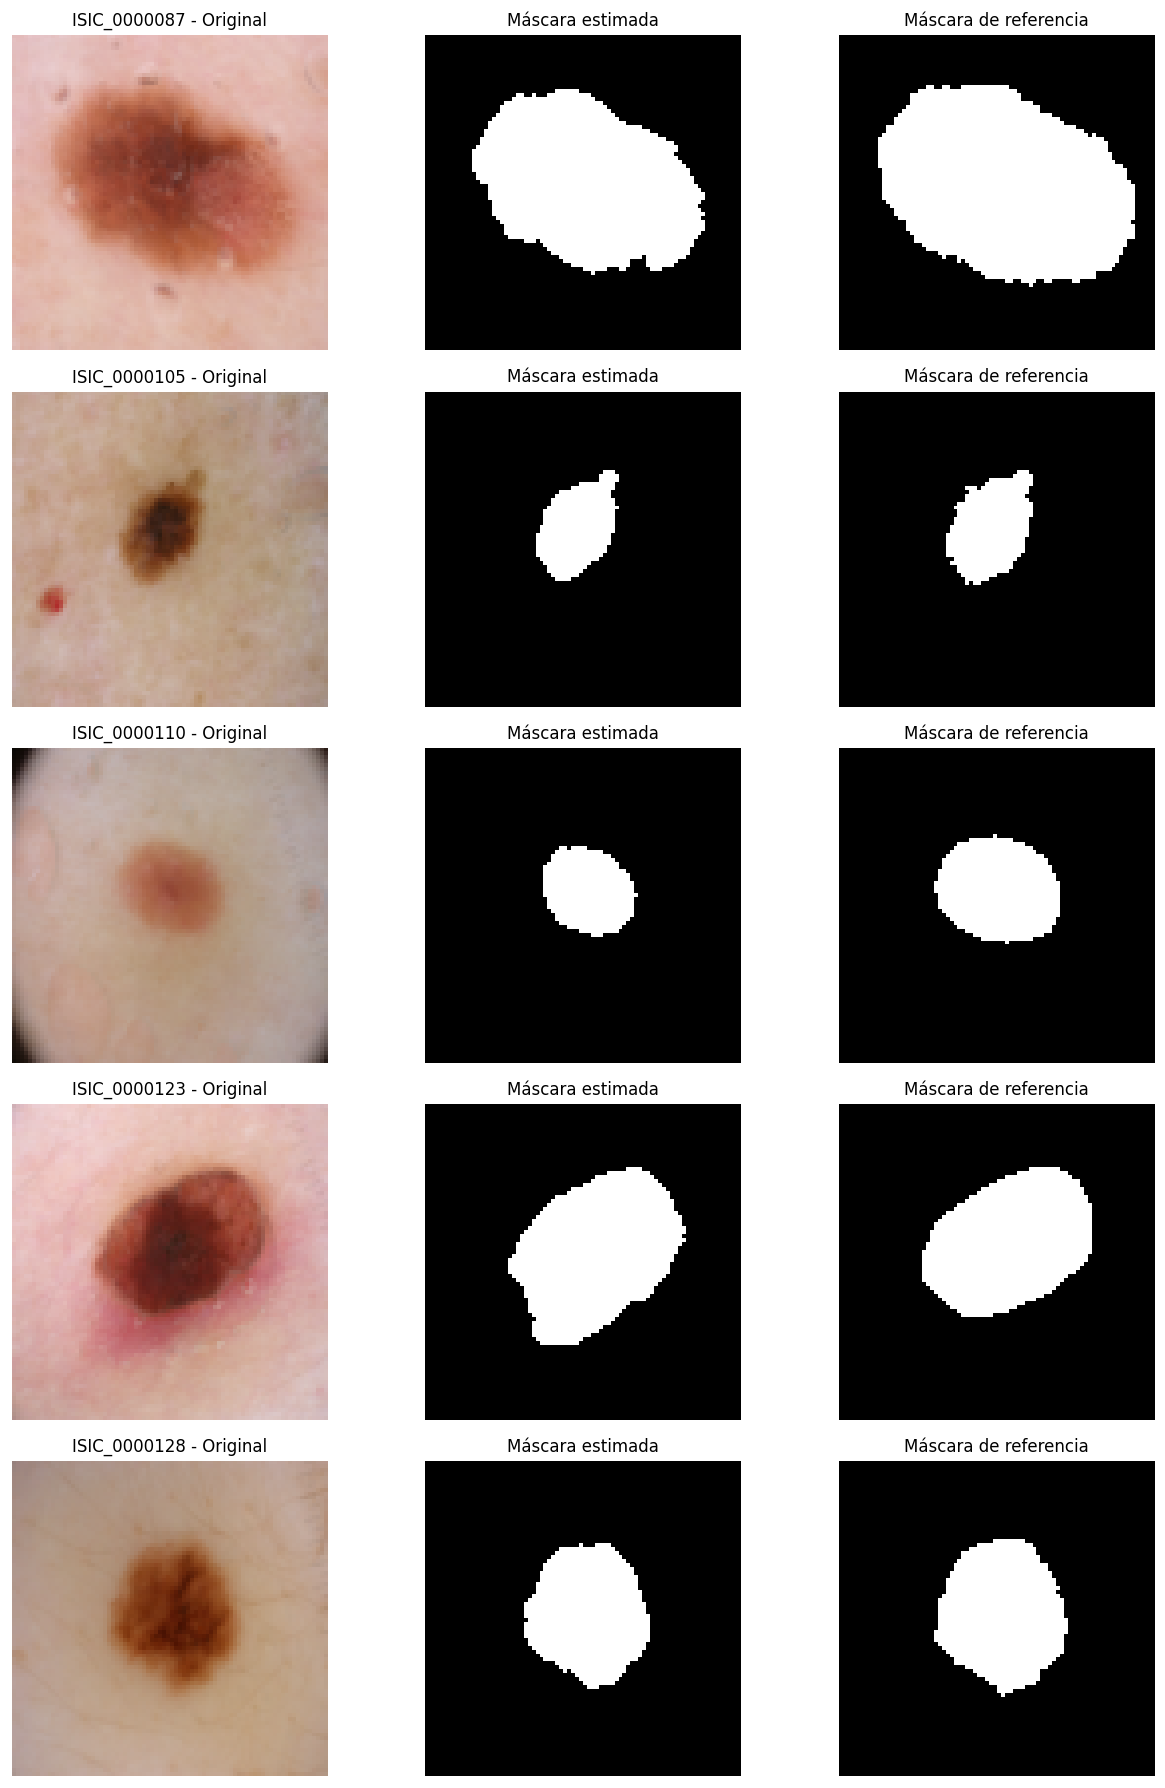

In [20]:
fig, axes = plt.subplots(len(PRUEBA), 3, figsize=(11, 15))
for fila, identificador in enumerate(PRUEBA):
    imagen, estimada, referencia = visualizaciones_prueba[identificador]
    for columna, (matriz, titulo, cmap) in enumerate([
        (imagen, "Original", None), (estimada, "Máscara estimada", "gray"),
        (referencia, "Máscara de referencia", "gray")]):
        axes[fila, columna].imshow(matriz, cmap=cmap, vmin=0 if cmap else None,
                                   vmax=1 if cmap else None)
        axes[fila, columna].set_title(f"{identificador} - Original" if columna == 0 else titulo, fontsize=10)
        axes[fila, columna].axis("off")
plt.tight_layout(); plt.show()

### 5.1. Comparación entre ajuste y prueba

El Dice promedio es **0,8917** en ajuste y **0,8840** en prueba: una diferencia de **0,0077**. La cercanía entre medias es favorable para este pequeño conjunto reservado, pero cinco imágenes no bastan para afirmar que el desempeño se mantendrá en otros centros o poblaciones. El caso de prueba más difícil es `ISIC_0000110` (Dice **0,759**, recall **0,612**): la lesión de bajo contraste queda parcialmente fuera. `ISIC_0000123` tiene precisión **0,856** y recall **0,957**; incluye parte del entorno rosado. Estos errores son distintos y deben revisarse por separado.

In [21]:
promedio_ajuste = seleccion_ajuste["Dice"].mean()
promedio_prueba = tabla_prueba["Dice"].mean()
comparacion = pd.DataFrame({"conjunto": ["ajuste", "prueba"],
                           "n_imagenes": [len(AJUSTE), len(PRUEBA)],
                           "Dice_promedio": [promedio_ajuste, promedio_prueba]})
display(comparacion.round(4))
print("Diferencia ajuste - prueba:", round(promedio_ajuste - promedio_prueba, 4))

Diferencia ajuste - prueba: 0.0077


,conjunto,n_imagenes,Dice_promedio
0,ajuste,15,0.8917
1,prueba,5,0.8840


## 6. Análisis de resultados

### 6.1. ¿Qué efecto tuvo incluir la posición?

La posición moderada mejora el promedio de **0,8857** (solo color) a **0,8917** (λ=0,2), principalmente por `ISIC_0000094`, cuya lesión tenue pasa de Dice **0,845** a **0,935**. En imágenes como `ISIC_0000133` el cambio es ligeramente desfavorable (**0,890** a **0,887**), y en la mayoría casi nulo porque K=2 sigue separando piel y lesión de forma parecida. Con solo posición, el Dice promedio cae a **0,3384**: la cercanía espacial forma regiones geométricas, pero no reconoce el contraste de la lesión. Al aumentar λ hasta 2, el Dice medio también cae, a **0,6025** con el criterio final.

### 6.2. ¿Qué relación hubo entre K, silueta y Dice?

La silueta seleccionó K=2 en **14 de 15** imágenes para la configuración final y K=4 en `ISIC_0000094`. Una silueta alta no garantiza buen Dice: `ISIC_0000116` tiene silueta **0,652** y Dice **0,755**, mientras que `ISIC_0000094` tiene silueta **0,355** y Dice **0,935**. La silueta evalúa distancias entre grupos en el espacio RGB + posición; Dice mide superposición con la lesión. El V-measure describe correspondencia entre grupos y referencia, pero tampoco decide por sí solo qué grupos forman la máscara.

### 6.3. ¿Cómo se comparan ajuste y prueba?

El promedio de prueba (**0,8840**) es cercano al de ajuste (**0,8917**), con diferencia **0,0077**. Aun así, el resultado de `ISIC_0000110` muestra variación importante entre imágenes. Cambiar λ, el umbral o la regla central después de mirar las máscaras de prueba convertiría este conjunto en parte del ajuste y daría una estimación optimista de la generalización.

### 6.4. Dos limitaciones del modelo

1. **Lesiones claras o bordes difusos.** El color RGB no distingue siempre la lesión de la piel. En `ISIC_0000116`, `ISIC_0000112` y `ISIC_0000110` se omiten zonas periféricas: sus recalls son **0,606**, **0,643** y **0,612**, respectivamente. La regla basada en oscuridad favorece el centro pigmentado y reduce el contorno.
2. **Dependencia del encuadre y del color de fondo.** La posición presume una lesión central y el contraste usa el borde como referencia de piel. Una lesión desplazada, un borde con sombra, pelo o iluminación desigual pueden cambiar los grupos y elegir un componente equivocado. La inclusión del entorno rosado en `ISIC_0000123` (precisión **0,856**) ilustra este riesgo.

### 6.5. Consecuencias y generalización en DermAlpes

Un **falso negativo** recorta la lesión y puede subestimar su tamaño o alterar la forma que revisa el dermatólogo. Un **falso positivo** agrega piel vecina y puede sobreestimar el área o hacer menos visible el borde real. La máscara debe tratarse como una ayuda revisable por el especialista.

El conjunto público contiene fotografías tomadas bajo condiciones particulares. Si los pacientes, tonos de piel, dispositivos, iluminación o protocolos de adquisición de los municipios difieren, puede haber **sesgo de muestra** y una caída del desempeño. Antes de uso real, DermAlpes necesitaría evaluación con datos locales representativos, revisión por subgrupos y supervisión humana. El método no identifica patologías ni reemplaza la valoración clínica.

## 7. Uso de herramientas de IA generativa

### 1. Herramienta utilizada

Durante el desarrollo de este laboratorio utilizamos **ChatGPT, de OpenAI**, como herramienta de apoyo para comprender algunos conceptos, revisar el código y mejorar las explicaciones de los resultados.

La herramienta nos ayudó principalmente a entender cómo aplicar K-medias para segmentar imágenes, cómo interpretar las métricas de evaluación y cómo identificar posibles errores en las máscaras obtenidas.

### Conclusión sobre el uso de IA generativa

Consideramos que ChatGPT fue una herramienta útil para apoyar el desarrollo del laboratorio, especialmente en la comprensión de conceptos, la identificación de errores y la interpretación de resultados.

Sin embargo, sus recomendaciones no reemplazan la necesidad de realizar experimentos. Aunque la configuración inicial obtuvo un Dice promedio de 0.825, encontramos una alternativa con un mejor resultado de 0.867 al comparar las configuraciones de manera sistemática.

### Evidencia de las interacciones

- ¿Me puedes explicar de manera más sencilla por qué es importante utilizar tanto el color como la posición de los píxeles?

- Quiero entender qué podría pasar si utilizo solamente el color o solamente la posición y por qué el valor de K puede cambiar los resultados de la segmentación.

- ¿Me puedes explicar qué significa este resultado y qué puedo concluir a partir de él?

- ¿Me puedes explicar cuál es la diferencia entre estas métricas? ¿Por qué puedo obtener un V-measure relativamente bueno y al mismo tiempo un Dice bajo?

- ¿Por qué pudo disminuir el desempeño del método? ¿Qué me dice esta diferencia sobre su capacidad para funcionar con imágenes nuevas?

## 8. Bonos

### Bono A. Visualización del espacio de representación con PCA

Se toma una muestra reproducible de 1.200 píxeles de una imagen de ajuste y se proyectan sus cinco características `[βR, βG, βB, λx, λy]` a dos componentes principales. Una gráfica usa el grupo de K-medias y la otra la máscara de referencia. Se conserva la configuración final; este bono no modifica la selección ni las métricas de prueba.

Varianza explicada por las dos componentes: 0.905


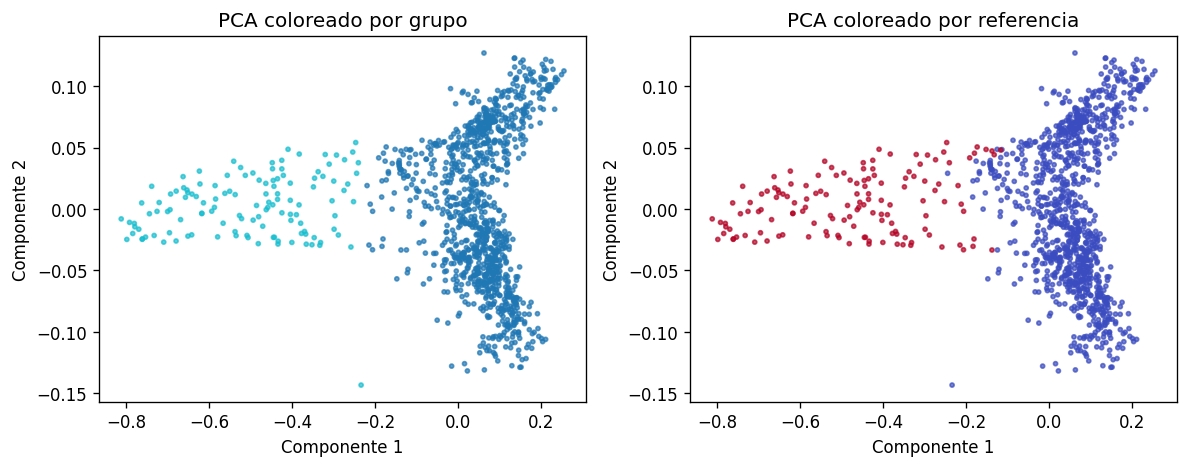

In [22]:
from sklearn.decomposition import PCA
identificador_pca = AJUSTE[0]
imagen_pca, referencia_pca = cargar_imagen(identificador_pca)
X_pca = Pipeline([("pixeles", PixelesRGBPosicion(1, .2))]).fit_transform(imagen_pca)
_, grupos_pca, _, _ = agrupar_y_evaluar(imagen_pca, referencia_pca, 1, .2)
indices_pca = np.random.default_rng(SEMILLA).choice(len(X_pca), 1200, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA)
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    proyeccion = pca.fit_transform(X_pca[indices_pca])
assert np.isfinite(proyeccion).all()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(proyeccion[:, 0], proyeccion[:, 1],
                c=grupos_pca.ravel()[indices_pca], s=6, cmap="tab10", alpha=.7)
axes[0].set_title("PCA coloreado por grupo")
axes[1].scatter(proyeccion[:, 0], proyeccion[:, 1],
                c=referencia_pca.ravel()[indices_pca], s=6, cmap="coolwarm", alpha=.7)
axes[1].set_title("PCA coloreado por referencia")
for ax in axes:
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")
plt.tight_layout(); plt.show()
print("Varianza explicada por las dos componentes:", round(pca.explained_variance_ratio_.sum(), 4))

En `ISIC_0000085`, las dos componentes explican **0,905** de la varianza de la muestra. La rama izquierda del plano reúne muchos píxeles del grupo asociado con la lesión y también muchos píxeles marcados como lesión en la referencia; cerca de la zona central hay mezcla. Esto muestra una correspondencia parcial entre grupos y máscara, sin convertir automáticamente un grupo en una lesión. PCA reduce cinco dimensiones a dos, por lo que la aparente separación en el plano no reemplaza el Dice ni el V-measure calculados sobre los resultados originales.

### Bono B. Comparación con mean shift

Mean shift busca centros en zonas de alta densidad del espacio de características, desplazando cada centro hacia el promedio de sus vecinos. El **ancho de banda** determina qué puntos se consideran vecinos: un valor pequeño suele separar más grupos y uno grande puede unir regiones distintas. Por eso **no se fija K**; el número de grupos resulta de los centros encontrados. Esta explicación sigue la [guía de agrupación](https://scikit-learn.org/stable/modules/clustering.html#mean-shift) y la [documentación de MeanShift](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html) de Scikit-learn.

Se usa `ISIC_0000085`, una imagen de **ajuste**, a 80 × 80 píxeles, con β=1 y λ=0,2. Para que la comparación sea manejable, ambos algoritmos se ajustan con los **mismos 800 píxeles** elegidos con semilla 2611 y asignan después los 6.400 píxeles. K-medias usa el K ya seleccionado en ajuste para esta imagen; mean shift estima el ancho de banda con el cuantil 0,20 de una muestra de 500 píxeles, sin mirar la máscara. Se aplica a ambos grupos el mismo criterio de contraste central.

Los tiempos de agrupación incluyen ajuste y asignación de todos los píxeles. Se muestra aparte el tiempo de estimación del ancho de banda; el tiempo de búsqueda de K del análisis principal no está incluido en el tiempo de K-medias. Los tiempos dependen del equipo y no son una comparación general de velocidad.

In [23]:
from time import perf_counter
from sklearn.cluster import MeanShift, estimate_bandwidth

id_bono = AJUSTE[0]
imagen_bono, referencia_bono = cargar_imagen(id_bono)
X_bono = Pipeline([("pixeles", PixelesRGBPosicion(1, .2))]).fit_transform(imagen_bono)
indices_bono = np.random.default_rng(SEMILLA).choice(len(X_bono), 800, replace=False)
muestra_bono = X_bono[indices_bono]
k_bono = int(seleccion_ajuste.set_index("imagen").loc[id_bono, "K"])

inicio = perf_counter()
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    modelo_k_bono = KMeans(n_clusters=k_bono, n_init=3, max_iter=100,
                           random_state=SEMILLA).fit(muestra_bono)
assert np.isfinite(modelo_k_bono.cluster_centers_).all()
grupos_k_bono = modelo_k_bono.predict(X_bono).reshape(imagen_bono.shape[:2])
tiempo_k = perf_counter() - inicio
mascara_k_bono = construir_mascara(imagen_bono, grupos_k_bono, "contraste_central")

t0 = perf_counter()
ancho_banda = estimate_bandwidth(muestra_bono, quantile=.20, n_samples=500,
                                random_state=SEMILLA, n_jobs=1)
tiempo_ancho = perf_counter() - t0
assert np.isfinite(ancho_banda) and ancho_banda > 0
inicio = perf_counter()
modelo_ms_bono = MeanShift(bandwidth=ancho_banda, bin_seeding=True,
                           min_bin_freq=3, cluster_all=True, n_jobs=1).fit(muestra_bono)
grupos_ms_bono = modelo_ms_bono.predict(X_bono).reshape(imagen_bono.shape[:2])
tiempo_ms = perf_counter() - inicio
mascara_ms_bono = construir_mascara(imagen_bono, grupos_ms_bono, "contraste_central")

comparacion_bono_b = pd.DataFrame([
    {"algoritmo": "K-medias", "grupos": k_bono,
     "Dice": f1_score(referencia_bono.ravel(), mascara_k_bono.ravel()),
     "tiempo_agrupar_s": tiempo_k, "tiempo_ancho_banda_s": 0.0,
     "tiempo_total_s": tiempo_k},
    {"algoritmo": "mean shift", "grupos": len(modelo_ms_bono.cluster_centers_),
     "Dice": f1_score(referencia_bono.ravel(), mascara_ms_bono.ravel()),
     "tiempo_agrupar_s": tiempo_ms, "tiempo_ancho_banda_s": tiempo_ancho,
     "tiempo_total_s": tiempo_ms + tiempo_ancho}
])
print("Imagen:", id_bono, "| ancho de banda estimado:", round(ancho_banda, 4))
display(comparacion_bono_b.round(4))

Imagen: ISIC_0000085 | ancho de banda estimado: 0.1579


,algoritmo,grupos,Dice,tiempo_agrupar_s,tiempo_ancho_banda_s,tiempo_total_s
0,K-medias,2,0.9114,0.0010,0.000,0.0010
1,mean shift,4,0.9729,0.0163,0.006,0.0223


Se representan los grupos producidos por cada algoritmo y las máscaras binarias construidas con ellos. La referencia aparece solo para comparar el resultado, no para fijar K ni el ancho de banda.

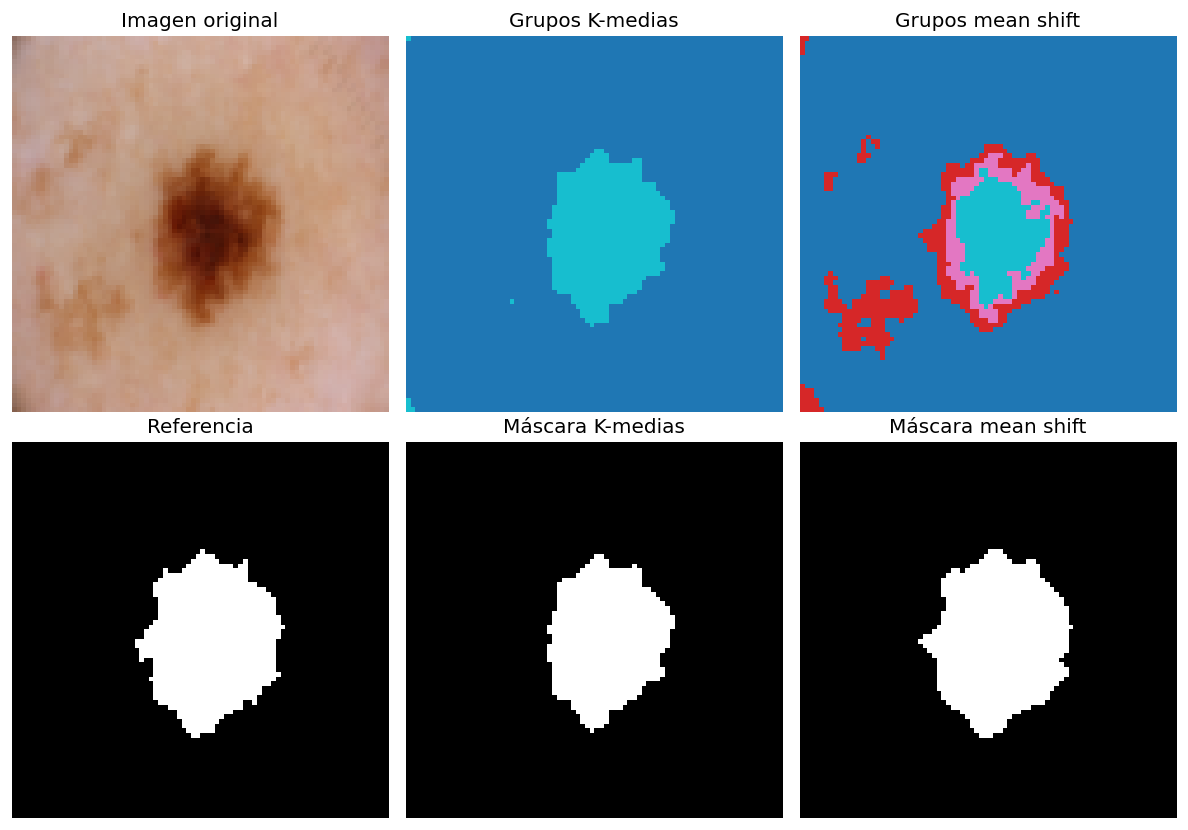

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, matriz, titulo, mapa in [
    (axes[0, 0], imagen_bono, "Imagen original", None),
    (axes[0, 1], grupos_k_bono, "Grupos K-medias", "tab10"),
    (axes[0, 2], grupos_ms_bono, "Grupos mean shift", "tab10"),
    (axes[1, 0], referencia_bono, "Referencia", "gray"),
    (axes[1, 1], mascara_k_bono, "Máscara K-medias", "gray"),
    (axes[1, 2], mascara_ms_bono, "Máscara mean shift", "gray")]:
    ax.imshow(matriz, cmap=mapa, vmin=0 if mapa == "gray" else None,
              vmax=1 if mapa == "gray" else None, interpolation="nearest")
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretación.** En esta imagen de ajuste, mean shift encontró más grupos que K-medias sin que se le indicara K. Su máscara coincide mejor con la referencia: el Dice pasa de **0,911** con K-medias a **0,973** con mean shift en esta comparación de muestra común. La diferencia se ve sobre todo en el contorno: mean shift separa varias tonalidades de la lesión y la regla del componente central descarta grupos oscuros aislados fuera de ella. Este resultado corresponde a **una sola imagen** y no modifica la configuración principal ni demuestra que mean shift vaya a superar a K-medias en las demás imágenes.

El ancho de banda estimado fue aproximadamente **0,158**. Cambiarlo puede alterar tanto el número de grupos como la máscara, por lo que también requiere una elección cuidadosa. Los tiempos medidos aparecen en la tabla. La comparación no incluye el mismo trabajo de selección de hiperparámetros y solo describe esta ejecución local; no permite concluir cuál algoritmo será siempre más rápido.